In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv("../data/lifestyle_disease_transformed.csv")

target = df.iloc[:,-1:].values
features = df.iloc[:,:-1].values


x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=1)

In [8]:
class Logistic_Regressor:
    def __init__(self, max_iter=1000, alpha=0.001):
        self.iter = max_iter
        self.alpha = alpha

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def fit(self, x_train, y_train):
        ones = np.ones((x_train.shape[0], 1))
        x_train = np.hstack((ones, x_train))
        
        y_train = y_train.reshape(-1, 1)
        
        self.w = np.zeros((x_train.shape[1], 1))
        
        for _ in range(self.iter):
            y_pred = self.sigmoid(x_train @ self.w)
            grad = x_train.T @ (y_train - y_pred)
            self.w += self.alpha * grad / len(y_train)

    def predict(self, x_test):
        ones = np.ones((x_test.shape[0], 1))
        x_test = np.hstack((ones, x_test))
        
        y_pred = self.sigmoid(x_test @ self.w)
        return (y_pred >= 0.5).astype(int)
    
    def getCoeff(self):
        return self.w
    
    def predict_proba(self, x_test):
        ones = np.ones((x_test.shape[0], 1))
        x_test = np.hstack((ones, x_test))
        
        y_pred = self.sigmoid(x_test @ self.w)
        
        # return probability of class 0 and class 1
        return np.hstack((1 - y_pred, y_pred))



In [9]:
model = Logistic_Regressor(1000)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
y_probs_matrix = model.predict_proba(x_test)
y_probs = y_probs_matrix[:, 1]

## Model Performance Report ##
------------------------------
              Score
Accuracy   0.812663
Precision  0.811535
Recall     0.468490
F1 Score   0.594044
ROC AUC    0.881744
------------------------------


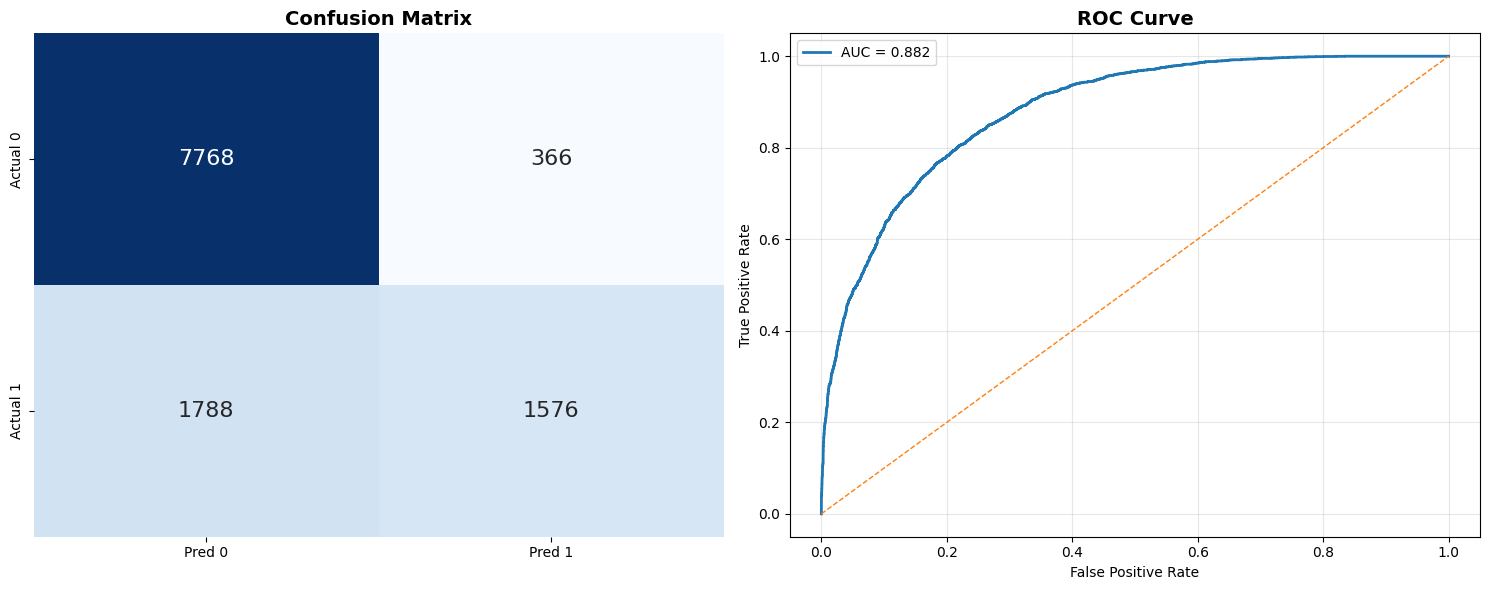

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

def report_statistical_outcomes(y_true, y_pred, y_probs=None, figsize=(15, 6)):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
    }

    if y_probs is not None:
        roc_score = roc_auc_score(y_true, y_probs)
        fpr, tpr, _ = roc_curve(y_true, y_probs)
    else:
        roc_score = roc_auc_score(y_true, y_pred)
        fpr, tpr, _ = roc_curve(y_true, y_pred)

    metrics["ROC AUC"] = roc_score

    print("## Model Performance Report ##")
    print("-" * 30)
    df_metrics = pd.DataFrame(metrics, index=[0]).T
    df_metrics.columns = ['Score']
    print(df_metrics)
    print("-" * 30)

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Pred 0', 'Pred 1'],
        yticklabels=['Actual 0', 'Actual 1'],
        ax=axes[0], annot_kws={"size": 16}
    )
    axes[0].set_title("Confusion Matrix", fontsize=14, fontweight='bold')

    axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {roc_score:.3f}')
    axes[1].plot([0, 1], [0, 1], linestyle='--', lw=1)
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title('ROC Curve', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


report_statistical_outcomes(y_test, y_pred, y_probs)